# **🛡️ NEXMIND CYBERSAFE AI**
```
An Intelligent Multi-Agent Cybersecurity Assistant
```


**Design, Development, Testing, and Deployment Using Python, LangGraph, Google Colab, and Telegram**


**Project Name:** CyberSafe AI

**Team Name:** NexMind

**Project Category:** Artificial Intelligence, Cybersecurity, and Multi-Agent Systems

**Development Environment:** Google Colab (Python)

**Application Platform:** Telegram

**Deployment Platform:** Render

1. **Introduction**

The increasing use of the internet, social media, online banking, and digital communication has exposed individuals and organizations to various cybersecurity threats. These include phishing messages, fraudulent websites, online scams, identity theft, and attempts to steal sensitive information such as passwords and One-Time Passwords (OTPs).

Many internet users, particularly those without technical knowledge, find it difficult to recognize suspicious messages or determine whether a website link is potentially dangerous.

To address this challenge, Team NexMind developed CyberSafe AI, a multi-agent cybersecurity assistant designed to help users identify potential online threats, assess risks, and receive understandable cybersecurity guidance.

CyberSafe AI is designed to make cybersecurity awareness and basic threat assessment more accessible to everyday internet users.

# **Part 1 — Building the three cybersecurity agents**

In [16]:

# STEP 1 — CYBERSAFE AI ENVIRONMENT SETUP

import sys
import subprocess
import importlib.metadata as metadata

packages = [
    "langgraph",
    "langchain-core",
    "fastapi",
    "uvicorn",
    "python-telegram-bot",
    "pydantic",
    "requests",
    "pandas",
    "scikit-learn"
]

print("Installing CyberSafe AI dependencies...")

subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "-q", *packages
])

print("\nCYBERSAFE AI — ENVIRONMENT CHECK")
print("=" * 45)
print("Python version:", sys.version.split()[0])

for package in packages:
    print(f"{package}: {metadata.version(package)}")

print("=" * 45)
print("STEP 1 COMPLETED SUCCESSFULLY")


Installing CyberSafe AI dependencies...

CYBERSAFE AI — ENVIRONMENT CHECK
Python version: 3.13.18
langgraph: 1.2.18
langchain-core: 1.7.0
fastapi: 0.141.1
uvicorn: 0.54.0
python-telegram-bot: 22.8
pydantic: 2.14.1
requests: 2.32.4
pandas: 2.2.3
scikit-learn: 1.6.1
STEP 1 COMPLETED SUCCESSFULLY


**STEP 1 — SETTING UP THE CYBERSAFE AI ENVIRONMENT**

Before developing CyberSafe AI, we install the software tools needed to build and operate the system. This is similar to preparing tools before starting a construction project.

The packages support AI agents, Telegram communication, web services, data processing, and testing.

The code then checks the installed versions to confirm that the environment is ready.

**Expected result**: STEP 1 COMPLETED SUCCESSFULLY.

In [17]:

# STEP 2 — CREATE CYBERSAFE AI PROJECT STRUCTURE

from pathlib import Path

# Main project directory
PROJECT_DIR = Path("/content/CyberSafe_AI")

# Define project folders
folders = [
    "agents",
    "orchestrator",
    "telegram_bot",
    "data",
    "results",
    "tests",
    "logs",
    "config"
]

# Create folders
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

for folder in folders:
    (PROJECT_DIR / folder).mkdir(
        parents=True,
        exist_ok=True
    )

# Create Python package initialization files
for folder in [
    "agents",
    "orchestrator",
    "telegram_bot",
    "config"
]:
    init_file = PROJECT_DIR / folder / "__init__.py"
    init_file.touch(exist_ok=True)

# Display project structure
print("=" * 55)
print("CYBERSAFE AI — PROJECT STRUCTURE")
print("=" * 55)

print("CyberSafe_AI/")

for folder in folders:
    print(f"  ├── {folder}/")

print("=" * 55)
print("Project location:", PROJECT_DIR)
print("STEP 2 COMPLETED SUCCESSFULLY")


CYBERSAFE AI — PROJECT STRUCTURE
CyberSafe_AI/
  ├── agents/
  ├── orchestrator/
  ├── telegram_bot/
  ├── data/
  ├── results/
  ├── tests/
  ├── logs/
  ├── config/
Project location: /content/CyberSafe_AI
STEP 2 COMPLETED SUCCESSFULLY


**Step 2: Creating the project folders**
In this step, we organize our CyberSafe AI project into separate folders.

Imagine an office with different departments. Each department handles a particular responsibility. Similarly, CyberSafe AI needs different folders for its agents, system coordination, Telegram bot, data, test results, and configuration.

The code creates these folders automatically inside a main folder called CyberSafe_AI.

This organization makes the project easier to manage, maintain, and improve.

**Expected result**: The names of the created folders will appear on the screen, followed by a successful completion message.

In [18]:

# STEP 3 — CYBERSAFE AI: THREAT DETECTION AGENT

from pathlib import Path
import textwrap
import importlib.util

PROJECT_DIR = Path("/content/CyberSafe_AI")
AGENT_FILE = PROJECT_DIR / "agents" / "detection.py"

agent_code = r'''
import re
import time

class ThreatDetectionAgent:

    def __init__(self):
        self.name = "Threat Detection Agent"

        self.patterns = {
            "urgency": [
                r"\bimmediately\b",
                r"\burgent\b",
                r"\bwithin \d+ (minutes?|hours?)\b",
                r"\baccount (will be )?(blocked|suspended)\b"
            ],
            "financial_lure": [
                r"\bcongratulations\b",
                r"\byou (have )?won\b",
                r"\bclaim your (prize|reward)\b",
                r"\bfree money\b"
            ],
            "sensitive_information": [
                r"\botp\b",
                r"\bbvn\b",
                r"\bpin\b",
                r"\bpassword\b",
                r"\bbank details\b"
            ],
            "suspicious_action": [
                r"\bclick (this |the )?link\b",
                r"\bverify your account\b",
                r"\bsend your details\b"
            ]
        }

    def analyze(self, message):
        start = time.perf_counter()

        if not isinstance(message, str):
            raise TypeError("Message must be a string")

        if not message.strip():
            raise ValueError("Message cannot be empty")

        indicators = []

        for category, patterns in self.patterns.items():
            for pattern in patterns:
                if re.search(pattern, message, re.IGNORECASE):
                    indicators.append(category)
                    break

        urls = re.findall(
            r'https?://[^\s<>"\']+',
            message,
            flags=re.IGNORECASE
        )

        indicators = sorted(set(indicators))

        result = {
            "agent": self.name,
            "indicators": indicators,
            "urls": urls,
            "indicator_count": len(indicators),
            "requires_verification": bool(indicators or urls),
            "execution_seconds": round(
                time.perf_counter() - start, 6
            )
        }

        return result
'''

# Save agent as a reusable Python module
AGENT_FILE.write_text(
    textwrap.dedent(agent_code),
    encoding="utf-8"
)

# Load the agent module
spec = importlib.util.spec_from_file_location(
    "detection", AGENT_FILE
)

module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

agent = module.ThreatDetectionAgent()

# Test with a simulated Nigerian phishing message
test_message = (
    "URGENT! Your bank account will be blocked "
    "within 30 minutes. Click this link "
    "https://example.com/verify and enter your BVN "
    "and OTP immediately."
)

result = agent.analyze(test_message)

print("=" * 55)
print("CYBERSAFE AI — AGENT 1 TEST")
print("=" * 55)

for key, value in result.items():
    print(f"{key}: {value}")

print("=" * 55)
print("STEP 3 COMPLETED SUCCESSFULLY")


CYBERSAFE AI — AGENT 1 TEST
agent: Threat Detection Agent
indicators: ['sensitive_information', 'suspicious_action', 'urgency']
urls: ['https://example.com/verify']
indicator_count: 3
requires_verification: True
execution_seconds: 0.000158
STEP 3 COMPLETED SUCCESSFULLY


**Step 3: Building Agent 1 — Threat Detection**
This step creates the first cybersecurity agent, called the Threat Detection Agent.

Its job is to examine messages and look for warning signs of possible online fraud, phishing, or scams.

For example, someone might receive this message:

"URGENT! Your bank account will be blocked. Click this link and send your OTP immediately."

The agent looks for suspicious expressions such as "urgent", "click this link", "OTP", and "account will be blocked".

It identifies these warning signs and prepares a report for the next agent.

Think of this agent as a security guard who checks people entering a building and identifies anything suspicious.

**Expected result:** The Threat Detection Agent is created and tested to see whether it can identify suspicious message patterns.

***Important:*** This agent uses predefined rules and patterns. Finding a warning sign does not automatically prove that a message is fraudulent.

In [19]:

# STEP 4 — CYBERSAFE AI: EVIDENCE VERIFICATION AGENT

from pathlib import Path
import importlib.util
import time

PROJECT_DIR = Path("/content/CyberSafe_AI")
AGENT_FILE = PROJECT_DIR / "agents" / "verification.py"

agent_code = '''
import time
import ipaddress
from urllib.parse import urlsplit

class EvidenceVerificationAgent:

    def __init__(self):
        self.name = "Evidence Verification Agent"

    def verify(self, detection_result):
        start = time.perf_counter()

        urls = detection_result.get("urls", [])
        findings = []

        for url in urls:
            warnings = []
            parsed = urlsplit(url)

            hostname = parsed.hostname or ""

            if parsed.scheme.lower() != "https":
                warnings.append("URL does not use HTTPS")

            if "@" in parsed.netloc:
                warnings.append(
                    "URL contains userinfo, which may hide the destination"
                )

            if not hostname:
                warnings.append("Missing or invalid hostname")

            try:
                address = ipaddress.ip_address(hostname)
                warnings.append("URL uses an IP address")
                if not address.is_global:
                    warnings.append(
                        "IP address is not globally routable"
                    )
            except ValueError:
                pass

            if hostname.startswith("xn--") or ".xn--" in hostname:
                warnings.append(
                    "Internationalized domain requires review"
                )

            findings.append({
                "url": url,
                "hostname": hostname,
                "warnings": warnings,
                "verification_status": "offline_checks_only",
                "reputation_checked": False
            })

        return {
            "agent": self.name,
            "findings": findings,
            "urls_checked": len(findings),
            "verification_complete": False,
            "execution_seconds": round(
                time.perf_counter() - start, 6
            )
        }
'''

AGENT_FILE.write_text(agent_code, encoding="utf-8")

# Load Agent 2
spec = importlib.util.spec_from_file_location(
    "verification", AGENT_FILE
)
module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

verification_agent = module.EvidenceVerificationAgent()

# Use Agent 1's result from Step 3
verification_result = verification_agent.verify(result)

print("=" * 55)
print("CYBERSAFE AI — AGENT 2 TEST")
print("=" * 55)

for key, value in verification_result.items():
    print(f"{key}: {value}")

print("=" * 55)
print("STEP 4 COMPLETED SUCCESSFULLY")


CYBERSAFE AI — AGENT 2 TEST
agent: Evidence Verification Agent
findings: [{'url': 'https://example.com/verify', 'hostname': 'example.com', 'warnings': [], 'verification_status': 'offline_checks_only', 'reputation_checked': False}]
urls_checked: 1
verification_complete: False
execution_seconds: 9.4e-05
STEP 4 COMPLETED SUCCESSFULLY


**Step 4: Building Agent 2 — Evidence Verification**
This step creates the second cybersecurity agent, called the Evidence Verification Agent.

After the first agent identifies a suspicious message, the second agent examines the web links found in that message.

For example, if someone sends a link claiming to be from a bank, this agent checks technical warning signs in the link.

It looks for issues such as missing HTTPS protection, unusual website addresses, and links that may disguise their real destination.

Think of this agent as an investigator who examines evidence collected by a security guard.

Its purpose is to provide additional information before the system makes a risk assessment.

**Expected result:** The Evidence Verification Agent is created and tested.

***Important:*** This is a technical link inspection, not a complete online fact-checking service. A link using HTTPS is not necessarily safe.

In [20]:

# STEP 4 — CYBERSAFE AI: EVIDENCE VERIFICATION AGENT

from pathlib import Path
import importlib.util
import time

PROJECT_DIR = Path("/content/CyberSafe_AI")
AGENT_FILE = PROJECT_DIR / "agents" / "verification.py"

agent_code = '''
import time
import ipaddress
from urllib.parse import urlsplit

class EvidenceVerificationAgent:

    def __init__(self):
        self.name = "Evidence Verification Agent"

    def verify(self, detection_result):
        start = time.perf_counter()

        urls = detection_result.get("urls", [])
        findings = []

        for url in urls:
            warnings = []
            parsed = urlsplit(url)

            hostname = parsed.hostname or ""

            if parsed.scheme.lower() != "https":
                warnings.append("URL does not use HTTPS")

            if "@" in parsed.netloc:
                warnings.append(
                    "URL contains userinfo, which may hide the destination"
                )

            if not hostname:
                warnings.append("Missing or invalid hostname")

            try:
                address = ipaddress.ip_address(hostname)
                warnings.append("URL uses an IP address")
                if not address.is_global:
                    warnings.append(
                        "IP address is not globally routable"
                    )
            except ValueError:
                pass

            if hostname.startswith("xn--") or ".xn--" in hostname:
                warnings.append(
                    "Internationalized domain requires review"
                )

            findings.append({
                "url": url,
                "hostname": hostname,
                "warnings": warnings,
                "verification_status": "offline_checks_only",
                "reputation_checked": False
            })

        return {
            "agent": self.name,
            "findings": findings,
            "urls_checked": len(findings),
            "verification_complete": False,
            "execution_seconds": round(
                time.perf_counter() - start, 6
            )
        }
'''

AGENT_FILE.write_text(agent_code, encoding="utf-8")

# Load Agent 2
spec = importlib.util.spec_from_file_location(
    "verification", AGENT_FILE
)
module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

verification_agent = module.EvidenceVerificationAgent()

# Use Agent 1's result from Step 3
verification_result = verification_agent.verify(result)

print("=" * 55)
print("CYBERSAFE AI — AGENT 2 TEST")
print("=" * 55)

for key, value in verification_result.items():
    print(f"{key}: {value}")

print("=" * 55)
print("STEP 4 COMPLETED SUCCESSFULLY")


CYBERSAFE AI — AGENT 2 TEST
agent: Evidence Verification Agent
findings: [{'url': 'https://example.com/verify', 'hostname': 'example.com', 'warnings': [], 'verification_status': 'offline_checks_only', 'reputation_checked': False}]
urls_checked: 1
verification_complete: False
execution_seconds: 6.1e-05
STEP 4 COMPLETED SUCCESSFULLY


In [21]:

# STEP 5 — CYBERSAFE AI: RISK ASSESSMENT AGENT

from pathlib import Path
import importlib.util

PROJECT_DIR = Path("/content/CyberSafe_AI")
AGENT_FILE = PROJECT_DIR / "agents" / "risk_assessment.py"

agent_code = '''
import time

class RiskAssessmentAgent:

    def __init__(self):
        self.name = "Risk Assessment and Response Agent"

    def assess(self, detection_result, verification_result):
        start = time.perf_counter()

        indicators = detection_result.get("indicators", [])
        findings = verification_result.get("findings", [])

        # Preliminary heuristic score, not a calibrated probability
        weights = {
            "urgency": 20,
            "financial_lure": 20,
            "sensitive_information": 35,
            "suspicious_action": 25
        }

        score = sum(
            weights.get(indicator, 0)
            for indicator in set(indicators)
        )

        warning_count = sum(
            len(finding.get("warnings", []))
            for finding in findings
        )

        score += min(warning_count * 10, 20)
        score = min(score, 100)

        if score >= 60:
            risk_level = "HIGH"
        elif score >= 30:
            risk_level = "MEDIUM"
        else:
            risk_level = "LOW"

        reasons = []

        descriptions = {
            "urgency": "Message uses urgency or pressure",
            "financial_lure": "Message contains a financial lure",
            "sensitive_information":
                "Message mentions sensitive credentials or information",
            "suspicious_action":
                "Message encourages a potentially risky action"
        }

        for indicator in sorted(set(indicators)):
            reasons.append(
                descriptions.get(indicator, indicator)
            )

        for finding in findings:
            reasons.extend(finding.get("warnings", []))

        recommendations = [
            "Do not share passwords, PINs, BVNs, or OTPs.",
            "Do not open suspicious links.",
            "Verify claims using official contact channels."
        ]

        if risk_level == "HIGH":
            recommendations.append(
                "Treat this message as potentially fraudulent "
                "until independently verified."
            )

        verification_complete = verification_result.get(
            "verification_complete", False
        )

        return {
            "agent": self.name,
            "risk_level": risk_level,
            "heuristic_score": score,
            "score_type": "rule_based_not_probability",
            "reasons": reasons,
            "recommendations": recommendations,
            "external_verification_complete": verification_complete,
            "assessment_note": (
                "Preliminary assessment only. "
                "This score is not a probability of fraud. "
                "A low score does not establish safety."
            ),
            "execution_seconds": round(
                time.perf_counter() - start, 6
            )
        }
'''

AGENT_FILE.write_text(agent_code, encoding="utf-8")

# Load Agent 3
spec = importlib.util.spec_from_file_location(
    "risk_assessment", AGENT_FILE
)

module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

risk_agent = module.RiskAssessmentAgent()

# Combine Agent 1 and Agent 2 outputs
risk_result = risk_agent.assess(
    result,
    verification_result
)

print("=" * 60)
print("CYBERSAFE AI — AGENT 3 TEST")
print("=" * 60)

for key, value in risk_result.items():
    print(f"{key}: {value}")

print("=" * 60)
print("STEP 5 COMPLETED SUCCESSFULLY")


CYBERSAFE AI — AGENT 3 TEST
agent: Risk Assessment and Response Agent
risk_level: HIGH
heuristic_score: 80
score_type: rule_based_not_probability
reasons: ['Message mentions sensitive credentials or information', 'Message encourages a potentially risky action', 'Message uses urgency or pressure']
recommendations: ['Do not share passwords, PINs, BVNs, or OTPs.', 'Do not open suspicious links.', 'Verify claims using official contact channels.', 'Treat this message as potentially fraudulent until independently verified.']
external_verification_complete: False
assessment_note: Preliminary assessment only. This score is not a probability of fraud. A low score does not establish safety.
execution_seconds: 3.1e-05
STEP 5 COMPLETED SUCCESSFULLY


**Step 5: Building Agent 3 — Risk Assessment and Response**
This step creates the third cybersecurity agent.

The first agent identifies suspicious signs, while the second agent examines the links. The third agent uses their findings to estimate how risky the message may be.

It assigns points to different warning signs. For example, requests for sensitive information such as passwords or OTPs receive a higher weight.

The agent combines these points into a risk score and prepares a response to help the user understand the danger and take appropriate precautions.

Think of this agent as a security supervisor who reviews the investigators' reports and recommends what should happen next.

**Expected result:** The Risk Assessment Agent is created and tested.

***Important:*** The risk score is based on manually assigned rules. It is not a scientifically calibrated probability that a message is a scam.

In [22]:

# STEP 6 — CYBERSAFE AI LANGGRAPH ORCHESTRATOR

from pathlib import Path
import sys
import time
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

PROJECT_DIR = Path("/content/CyberSafe_AI")
sys.path.insert(0, str(PROJECT_DIR))

from agents.detection import ThreatDetectionAgent
from agents.verification import EvidenceVerificationAgent
from agents.risk_assessment import RiskAssessmentAgent

# Initialize the three agents
detection_agent = ThreatDetectionAgent()
verification_agent = EvidenceVerificationAgent()
risk_agent = RiskAssessmentAgent()

# Shared state for our LangGraph workflow
class CyberSafeState(TypedDict, total=False):
    message: str
    detection_result: dict
    verification_result: dict
    risk_result: dict

# Agent 1 node
def detect_threat(state: CyberSafeState):
    result = detection_agent.analyze(state["message"])
    return {"detection_result": result}

# Agent 2 node
def verify_evidence(state: CyberSafeState):
    result = verification_agent.verify(
        state["detection_result"]
    )
    return {"verification_result": result}

# Agent 3 node
def assess_risk(state: CyberSafeState):
    result = risk_agent.assess(
        state["detection_result"],
        state["verification_result"]
    )
    return {"risk_result": result}

# Build LangGraph workflow
workflow = StateGraph(CyberSafeState)

workflow.add_node("threat_detection", detect_threat)
workflow.add_node("evidence_verification", verify_evidence)
workflow.add_node("risk_assessment", assess_risk)

workflow.add_edge(START, "threat_detection")
workflow.add_edge(
    "threat_detection",
    "evidence_verification"
)
workflow.add_edge(
    "evidence_verification",
    "risk_assessment"
)
workflow.add_edge("risk_assessment", END)

cybersafe_graph = workflow.compile()

# Test the complete multi-agent system
test_message = (
    "URGENT! Your bank account will be blocked "
    "within 30 minutes. Click this link "
    "https://example.com/verify and enter "
    "your BVN and OTP immediately."
)

start_time = time.perf_counter()

final_state = cybersafe_graph.invoke({
    "message": test_message
})

total_time = time.perf_counter() - start_time

print("=" * 60)
print("CYBERSAFE AI — MULTI-AGENT SYSTEM TEST")
print("=" * 60)

print("\nAGENT 1 — THREAT DETECTION")
print(final_state["detection_result"])

print("\nAGENT 2 — EVIDENCE VERIFICATION")
print(final_state["verification_result"])

print("\nAGENT 3 — RISK ASSESSMENT")
print(final_state["risk_result"])

print("\n" + "=" * 60)
print("FINAL SECURITY REPORT")
print("=" * 60)

risk = final_state["risk_result"]

print("Risk Level:", risk["risk_level"])
print("Heuristic Score:", risk["heuristic_score"])
print("Reasons:", risk["reasons"])
print("Recommendations:", risk["recommendations"])
print(
    "External Verification Complete:",
    risk["external_verification_complete"]
)
print("Total Execution Time:", round(total_time, 6), "seconds")

print("=" * 60)
print("STEP 6 COMPLETED SUCCESSFULLY")


CYBERSAFE AI — MULTI-AGENT SYSTEM TEST

AGENT 1 — THREAT DETECTION
{'agent': 'Threat Detection Agent', 'indicators': ['sensitive_information', 'suspicious_action', 'urgency'], 'urls': ['https://example.com/verify'], 'indicator_count': 3, 'requires_verification': True, 'execution_seconds': 6.9e-05}

AGENT 2 — EVIDENCE VERIFICATION
{'agent': 'Evidence Verification Agent', 'findings': [{'url': 'https://example.com/verify', 'hostname': 'example.com', 'warnings': [], 'verification_status': 'offline_checks_only', 'reputation_checked': False}], 'urls_checked': 1, 'verification_complete': False, 'execution_seconds': 4.3e-05}

AGENT 3 — RISK ASSESSMENT
{'agent': 'Risk Assessment and Response Agent', 'risk_level': 'HIGH', 'heuristic_score': 80, 'score_type': 'rule_based_not_probability', 'reasons': ['Message mentions sensitive credentials or information', 'Message encourages a potentially risky action', 'Message uses urgency or pressure'], 'recommendations': ['Do not share passwords, PINs, BVNs,

**Step 6: Connecting the three agents using LangGraph**
Now that the three agents have been created, we need to make them work together.

This step uses a tool called LangGraph to coordinate their activities.

Think of LangGraph as a project manager in an organization. Instead of allowing everyone to work without direction, the manager ensures that tasks are completed in the correct order.

When a user submits a message, the system follows this process:
1. Agent 1 examines the message for suspicious signs.
2. Agent 2 checks the available link evidence.
3. Agent 3 assesses the risk and prepares safety advice.
The system then combines their findings into a final result.

**Expected result:** A working workflow that connects all three agents and allows them to process messages together.
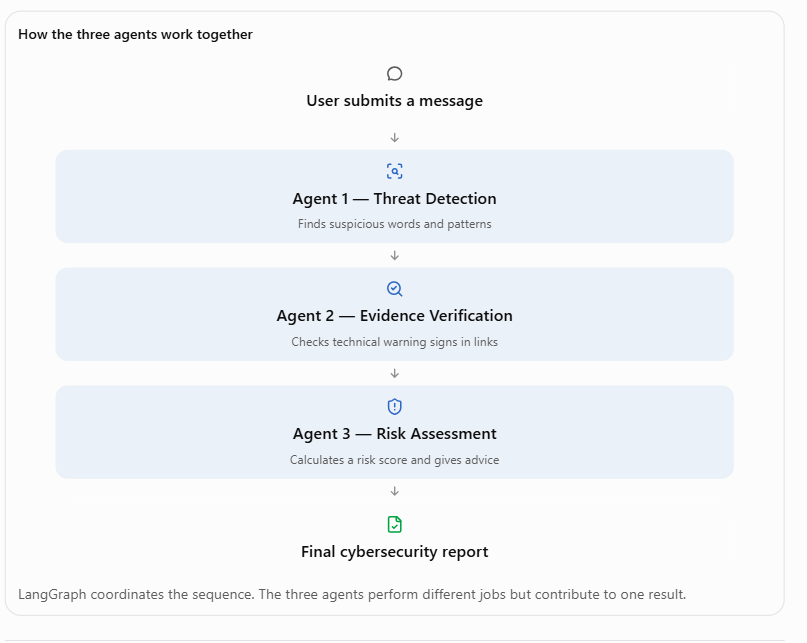

# **Part 2 — Connecting CyberSafe AI to Telegram**

In [24]:

# STEP 7A — ALTERNATIVE TELEGRAM CONNECTION

import getpass
import requests

print("=" * 55)
print("CYBERSAFE AI — TELEGRAM CONNECTION TEST")
print("=" * 55)

# Hidden token input
BOT_TOKEN = getpass.getpass(
    "Enter your Telegram bot token (hidden): "
).strip()

if not BOT_TOKEN:
    raise ValueError("Telegram bot token cannot be empty.")

try:
    response = requests.get(
        f"https://api.telegram.org/bot{BOT_TOKEN}/getMe",
        timeout=20
    )

    response.raise_for_status()
    data = response.json()

    if data.get("ok"):
        bot = data["result"]

        print("\nTelegram connection: SUCCESS")
        print("Bot name:", bot.get("first_name"))
        print("Bot username:", bot.get("username"))
        print("Bot ID:", bot.get("id"))
        print("=" * 55)
        print("STEP 7A COMPLETED SUCCESSFULLY")

    else:
        print("Telegram rejected the bot token.")

except requests.exceptions.Timeout:
    print("Connection timed out. Check network access.")

except requests.exceptions.RequestException:
    print("Telegram connection failed.")
    print("Check the token and internet connection.")


CYBERSAFE AI — TELEGRAM CONNECTION TEST
Enter your Telegram bot token (hidden): ··········

Telegram connection: SUCCESS
Bot name: Nexmind CyberSafeAI
Bot username: NexmindCybersafe_bot
Bot ID: 9242996300
STEP 7A COMPLETED SUCCESSFULLY


**Step 7A: Connecting to Telegram**
This step connects our CyberSafe AI system to a Telegram bot.

Telegram is a messaging platform where users can communicate with CyberSafe AI without opening Google Colab.

To make the connection, we need a Telegram bot token. Think of this token as a special key that allows our Python program to communicate with our Telegram bot.

The code asks us to enter the token privately. It then contacts Telegram to check whether the token is valid.

**Expected result:** Telegram confirms the connection and displays the bot's name, username, and identification number.

***Security note:*** Never share the bot token publicly or include it in a GitHub repository.

In [26]:

# STEP 7B — SEND CYBERSAFE AI REPORT TO TELEGRAM

import requests
import time

print("=" * 60)
print("CYBERSAFE AI — TELEGRAM INTEGRATION TEST")
print("=" * 60)

# BOT_TOKEN and cybersafe_graph come from earlier steps

if "BOT_TOKEN" not in globals():
    raise RuntimeError(
        "BOT_TOKEN missing. Run Step 7A first."
    )

if "cybersafe_graph" not in globals():
    raise RuntimeError(
        "LangGraph missing. Run Step 6 first."
    )

# Retrieve updates to identify our test chat
response = requests.get(
    f"https://api.telegram.org/bot{BOT_TOKEN}/getUpdates",
    params={"timeout": 0, "limit": 20},
    timeout=15
)
response.raise_for_status()

updates = response.json().get("result", [])

private_chats = [
    update["message"]["chat"]["id"]
    for update in updates
    if "message" in update
    and update["message"]["chat"]["type"] == "private"
]

if not private_chats:
    raise RuntimeError(
        "No private chat found. Open your Telegram bot, "
        "send /start, then run this cell again. "
        "If a webhook is active, it must be disabled "
        "before using getUpdates."
    )

chat_id = private_chats[-1]

# Simulated phishing message
test_message = (
    "URGENT! Your bank account will be blocked "
    "within 30 minutes. Click this link "
    "https://example.com/verify and enter "
    "your BVN and OTP immediately."
)

# Run the three agents
start = time.perf_counter()

state = cybersafe_graph.invoke({
    "message": test_message
})

risk = state["risk_result"]

elapsed = time.perf_counter() - start

# Format Telegram report
reasons = "\n".join(
    f"- {reason}"
    for reason in risk["reasons"]
)

recommendations = "\n".join(
    f"- {item}"
    for item in risk["recommendations"]
)

report = (
    "CYBERSAFE AI — SECURITY REPORT\n\n"
    f"Risk Level: {risk['risk_level']}\n"
    f"Heuristic Score: {risk['heuristic_score']}/100\n\n"
    f"Reasons:\n{reasons}\n\n"
    f"Recommendations:\n{recommendations}\n\n"
    "External verification: Not completed\n"
    "Note: This score is not a probability of fraud.\n"
    f"Analysis time: {elapsed:.4f} seconds"
)

# Send report to Telegram
send_response = requests.post(
    f"https://api.telegram.org/bot{BOT_TOKEN}/sendMessage",
    json={
        "chat_id": chat_id,
        "text": report
    },
    timeout=20
)

send_response.raise_for_status()

if not send_response.json().get("ok"):
    raise RuntimeError("Telegram rejected the message.")

print("Telegram message sent successfully!")
print("Risk Level:", risk["risk_level"])
print("Heuristic Score:", risk["heuristic_score"])
print("Total Analysis Time:", round(elapsed, 6))
print("=" * 60)
print("STEP 7B COMPLETED SUCCESSFULLY")


CYBERSAFE AI — TELEGRAM INTEGRATION TEST
Telegram message sent successfully!
Risk Level: HIGH
Heuristic Score: 80
Total Analysis Time: 0.002823
STEP 7B COMPLETED SUCCESSFULLY


**Step 7B: Sending a CyberSafe AI report to Telegram**
After connecting to Telegram, we need to confirm that CyberSafe AI can send messages to users.

This step retrieves recent Telegram messages to identify a test conversation.

It then uses the CyberSafe AI workflow to analyze a message and send the resulting cybersecurity report through Telegram.

Think of this as testing whether a customer service office can send its findings back to a customer.

**Expected result:** The Telegram bot sends a cybersecurity analysis report to the test chat.

This test may require sending a message to the bot first. It also depends on Telegram's update retrieval being available.

In [27]:

# STEP 7C — AUTOMATIC TELEGRAM MESSAGE HANDLING

import asyncio
import logging
from telegram import Update
from telegram.ext import (
    ApplicationBuilder,
    CommandHandler,
    MessageHandler,
    ContextTypes,
    filters
)

# Reduce unnecessary logging
logging.basicConfig(level=logging.WARNING)

if "BOT_TOKEN" not in globals():
    raise RuntimeError("Run Step 7A first.")

if "cybersafe_graph" not in globals():
    raise RuntimeError("Run Step 6 first.")

# Welcome command
async def start_command(
    update: Update,
    context: ContextTypes.DEFAULT_TYPE
):
    await update.message.reply_text(
        "Welcome to NexMind CyberSafe AI!\n\n"
        "Send me a suspicious message or link, "
        "and I will analyze it using our "
        "three-agent cybersecurity system.\n\n"
        "Never share your passwords, PINs, "
        "BVNs, or OTPs with this bot."
    )

# Analyze incoming messages
async def analyze_message(
    update: Update,
    context: ContextTypes.DEFAULT_TYPE
):
    message = update.message.text

    if not message or not message.strip():
        return

    if len(message) > 4000:
        await update.message.reply_text(
            "Please send a message under 4000 characters."
        )
        return

    await update.message.reply_text(
        "CyberSafe AI is analyzing your message..."
    )

    try:
        # Run LangGraph outside the event loop
        state = await asyncio.to_thread(
            cybersafe_graph.invoke,
            {"message": message}
        )

        risk = state["risk_result"]

        reasons = "\n".join(
            f"• {reason}"
            for reason in risk["reasons"]
        ) or "No matching warning patterns identified."

        recommendations = "\n".join(
            f"• {item}"
            for item in risk["recommendations"]
        )

        report = (
            "CYBERSAFE AI — SECURITY REPORT\n\n"
            f"Risk Level: {risk['risk_level']}\n"
            f"Heuristic Score: {risk['heuristic_score']}/100\n\n"
            f"Reasons:\n{reasons}\n\n"
            f"Recommendations:\n{recommendations}\n\n"
            "External verification: Incomplete\n"
            "This score is not a probability of fraud. "
            "A low score does not establish safety."
        )

        await update.message.reply_text(report)

    except Exception:
        logging.exception("Analysis failed")
        await update.message.reply_text(
            "Analysis could not be completed. "
            "Please try again later."
        )

# Build Telegram application
telegram_app = (
    ApplicationBuilder()
    .token(BOT_TOKEN)
    .build()
)

telegram_app.add_handler(
    CommandHandler("start", start_command)
)

telegram_app.add_handler(
    MessageHandler(
        filters.TEXT & ~filters.COMMAND,
        analyze_message
    )
)

# Colab already runs an event loop.
# This allows run_polling() to work in the notebook.
import nest_asyncio
nest_asyncio.apply()

print("=" * 60)
print("CYBERSAFE AI — LIVE TELEGRAM BOT")
print("=" * 60)
print("Bot: @NexmindCybersafe_bot")
print("Starting automatic message handling...")
print(telegram_app.run_polling(
    drop_pending_updates=True,
    close_loop=False
) * 60)



CYBERSAFE AI — LIVE TELEGRAM BOT
Bot: @NexmindCybersafe_bot
Starting automatic message handling...


TypeError: unsupported operand type(s) for *: 'NoneType' and 'int'

**Step 7C: Making Telegram respond automatically**
Previously, we tested sending a report to Telegram manually.

Now we want the bot to respond when someone sends it a message.

This step creates automatic message-handling functions.

For example, when a user starts a conversation, the bot can send a welcome message. When the user submits a suspicious message, the bot can analyze it using the three cybersecurity agents and return safety advice.

Think of this as changing from a manually operated customer service desk to an automated help desk.

**Expected result:** The bot's automatic message-handling functionality is defined and can be tested.

This Colab-based approach is useful for development, but it does not provide reliable 24-hour operation because Colab sessions can disconnect.

# **Part 3 — Preparing CyberSafe AI for online deployment**

In [28]:

# STEP 8A — BACK UP CYBERSAFE AI TO GOOGLE DRIVE

from google.colab import drive
from pathlib import Path
import shutil
import time

print("=" * 60)
print("CYBERSAFE AI — GOOGLE DRIVE BACKUP")
print("=" * 60)

# Mount Google Drive
drive.mount("/content/drive")

# Source project
source = Path("/content/CyberSafe_AI")

# Permanent backup location
backup = Path(
    "/content/drive/MyDrive/NexMind/CyberSafe_AI"
)

if not source.exists():
    raise FileNotFoundError(
        "CyberSafe AI project folder not found. "
        "Check whether the Colab runtime was reset."
    )

# Create destination folder
backup.parent.mkdir(
    parents=True,
    exist_ok=True
)

# Copy project files to Drive
shutil.copytree(
    source,
    backup,
    dirs_exist_ok=True,
    ignore=shutil.ignore_patterns(
        "__pycache__",
        "*.pyc",
        ".env",
        ".env.*",
        "*.log",
        ".git"
    )
)

# Verify important files
required_files = [
    "agents/detection.py",
    "agents/verification.py",
    "agents/risk_assessment.py"
]

print("\nChecking backed-up agent files:")

for filename in required_files:
    file_path = backup / filename

    if not file_path.exists():
        raise FileNotFoundError(
            f"Backup verification failed: {filename}"
        )

    print("OK:", filename)

print("\nBackup location:", backup)
print("Backup time:", time.ctime())

print("=" * 60)
print("STEP 8A COMPLETED SUCCESSFULLY")


CYBERSAFE AI — GOOGLE DRIVE BACKUP
Mounted at /content/drive

Checking backed-up agent files:
OK: agents/detection.py
OK: agents/verification.py
OK: agents/risk_assessment.py

Backup location: /content/drive/MyDrive/NexMind/CyberSafe_AI
Backup time: Mon Nov  2 13:59:16 2026
STEP 8A COMPLETED SUCCESSFULLY


**Step 8A: Backing up the project to Google Drive**
Google Colab does not guarantee permanent storage of files created inside its temporary working environment.

If the session restarts, we may lose project files that have not been saved elsewhere.

This step connects Colab to Google Drive and copies our CyberSafe AI project into a permanent backup folder.

The backup location is:

MyDrive/NexMind/CyberSafe_AI

Think of this as keeping an important document in a safe place rather than leaving it on a temporary desk.

**Expected result:** The project files are copied to Google Drive.

This protects our work from accidental loss when Colab disconnects, although later changes must also be backed up.

In [29]:

# STEP 8B — CREATE CYBERSAFE AI FASTAPI APPLICATION

from pathlib import Path
import textwrap
import ast

PROJECT_DIR = Path("/content/CyberSafe_AI")
MAIN_FILE = PROJECT_DIR / "main.py"

main_code = r'''
import os
import asyncio
from typing import TypedDict

from fastapi import FastAPI, Request, HTTPException
from telegram import Bot
from langgraph.graph import StateGraph, START, END

from agents.detection import ThreatDetectionAgent
from agents.verification import EvidenceVerificationAgent
from agents.risk_assessment import RiskAssessmentAgent

app = FastAPI(title="NexMind CyberSafe AI")

detection_agent = ThreatDetectionAgent()
verification_agent = EvidenceVerificationAgent()
risk_agent = RiskAssessmentAgent()


class CyberSafeState(TypedDict, total=False):
    message: str
    detection_result: dict
    verification_result: dict
    risk_result: dict


def detect_threat(state: CyberSafeState):
    return {
        "detection_result": detection_agent.analyze(
            state["message"]
        )
    }


def verify_evidence(state: CyberSafeState):
    return {
        "verification_result": verification_agent.verify(
            state["detection_result"]
        )
    }


def assess_risk(state: CyberSafeState):
    return {
        "risk_result": risk_agent.assess(
            state["detection_result"],
            state["verification_result"]
        )
    }


workflow = StateGraph(CyberSafeState)

workflow.add_node("detection", detect_threat)
workflow.add_node("verification", verify_evidence)
workflow.add_node("assessment", assess_risk)

workflow.add_edge(START, "detection")
workflow.add_edge("detection", "verification")
workflow.add_edge("verification", "assessment")
workflow.add_edge("assessment", END)

cybersafe_graph = workflow.compile()


@app.get("/health")
async def health():
    return {"status": "ok", "service": "CyberSafe AI"}


@app.post("/telegram/webhook")
async def telegram_webhook(request: Request):
    secret = os.getenv("TELEGRAM_WEBHOOK_SECRET")
    token = os.getenv("TELEGRAM_BOT_TOKEN")

    if not secret or not token:
        raise HTTPException(
            status_code=503,
            detail="Telegram integration not configured"
        )

    supplied = request.headers.get(
        "X-Telegram-Bot-Api-Secret-Token", ""
    )

    import hmac
    if not hmac.compare_digest(supplied, secret):
        raise HTTPException(
            status_code=403,
            detail="Invalid webhook secret"
        )

    payload = await request.json()
    message = payload.get("message", {})
    text = message.get("text", "")
    chat_id = message.get("chat", {}).get("id")

    if not chat_id or not text:
        return {"ok": True, "processed": False}

    if text.startswith("/start"):
        reply = (
            "Welcome to NexMind CyberSafe AI! "
            "Send a suspicious message for analysis. "
            "Never send your passwords, PINs, BVNs or OTPs."
        )
    elif len(text) > 4000:
        reply = "Please send a message under 4000 characters."
    else:
        state = await asyncio.to_thread(
            cybersafe_graph.invoke,
            {"message": text}
        )

        risk = state["risk_result"]

        reasons = "\\n".join(
            "- " + item for item in risk["reasons"]
        )

        recommendations = "\\n".join(
            "- " + item for item in risk["recommendations"]
        )

        reply = (
            f"CYBERSAFE AI SECURITY REPORT\\n\\n"
            f"Risk Level: {risk['risk_level']}\\n"
            f"Heuristic Score: {risk['heuristic_score']}/100\\n\\n"
            f"Reasons:\\n{reasons}\\n\\n"
            f"Recommendations:\\n{recommendations}\\n\\n"
            "External verification is incomplete. "
            "This score is not a probability of fraud."
        )

    async with Bot(token=token) as bot:
        await bot.send_message(
            chat_id=chat_id,
            text=reply
        )

    return {"ok": True}
'''

PROJECT_DIR.mkdir(parents=True, exist_ok=True)

MAIN_FILE.write_text(
    textwrap.dedent(main_code),
    encoding="utf-8"
)

# Check Python syntax without starting a server
ast.parse(MAIN_FILE.read_text(encoding="utf-8"))

# Copy to Google Drive backup
DRIVE_FILE = Path(
    "/content/drive/MyDrive/NexMind/CyberSafe_AI/main.py"
)

DRIVE_FILE.parent.mkdir(
    parents=True,
    exist_ok=True
)

DRIVE_FILE.write_text(
    MAIN_FILE.read_text(encoding="utf-8"),
    encoding="utf-8"
)

print("=" * 60)
print("CYBERSAFE AI — FASTAPI DEPLOYMENT FILE")
print("=" * 60)
print("Created:", MAIN_FILE)
print("Backed up:", DRIVE_FILE)
print("Python syntax: VALID")
print("Health endpoint: /health")
print("Telegram endpoint: /telegram/webhook")
print("=" * 60)
print("STEP 8B COMPLETED SUCCESSFULLY")


CYBERSAFE AI — FASTAPI DEPLOYMENT FILE
Created: /content/CyberSafe_AI/main.py
Backed up: /content/drive/MyDrive/NexMind/CyberSafe_AI/main.py
Python syntax: VALID
Health endpoint: /health
Telegram endpoint: /telegram/webhook
STEP 8B COMPLETED SUCCESSFULLY


**Step 8B: Creating the FastAPI application**
This step prepares CyberSafe AI to operate as an online service.

So far, we have been running our Python code inside Google Colab. However, we want Telegram to communicate with our system through the internet.

FastAPI is a Python tool that allows us to create a web service.

Think of FastAPI as a reception desk that receives requests from Telegram, passes them to the cybersecurity agents, and returns the results.

The code creates the main application file, main.py, which connects the three agents to the web service.

**Expected result:** The main FastAPI application file is created.
This step prepares the application for online hosting but does not yet publish it on the internet

In [30]:

# STEP 8C — CYBERSAFE AI FASTAPI TEST

import sys
import os
import asyncio
from pathlib import Path

from fastapi.testclient import TestClient

PROJECT_DIR = Path("/content/CyberSafe_AI")

# Confirm required files exist
required_files = [
    "main.py",
    "agents/detection.py",
    "agents/verification.py",
    "agents/risk_assessment.py"
]

for filename in required_files:
    if not (PROJECT_DIR / filename).exists():
        raise FileNotFoundError(
            f"Missing project file: {filename}"
        )

# Allow Python to import the project
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from main import app, cybersafe_graph

print("=" * 60)
print("CYBERSAFE AI — FASTAPI APPLICATION TEST")
print("=" * 60)

# TEST 1 — Health endpoint
with TestClient(app) as client:
    response = client.get("/health")

    print("\nTEST 1 — HEALTH ENDPOINT")
    print("HTTP status:", response.status_code)
    print("Response:", response.json())

    assert response.status_code == 200
    assert response.json()["status"] == "ok"

    # TEST 2 — Unauthorized webhook request
    print("\nTEST 2 — WEBHOOK SECURITY")

    response = client.post(
        "/telegram/webhook",
        json={
            "message": {
                "chat": {"id": 12345},
                "text": "Test message"
            }
        }
    )

    print("HTTP status:", response.status_code)

    assert response.status_code in [403, 503]

# TEST 3 — LangGraph integration
print("\nTEST 3 — MULTI-AGENT WORKFLOW")

test_message = (
    "URGENT! Your account will be blocked. "
    "Click this link and send your OTP."
)

state = cybersafe_graph.invoke({
    "message": test_message
})

risk = state["risk_result"]

print("Risk level:", risk["risk_level"])
print("Heuristic score:", risk["heuristic_score"])
print("Agents executed: 3")

assert risk["risk_level"] == "HIGH"
assert risk["heuristic_score"] == 80

print("\n" + "=" * 60)
print("STEP 8C COMPLETED SUCCESSFULLY")
print("=" * 60)


CYBERSAFE AI — FASTAPI APPLICATION TEST

TEST 1 — HEALTH ENDPOINT
HTTP status: 200
Response: {'status': 'ok', 'service': 'CyberSafe AI'}

TEST 2 — WEBHOOK SECURITY
HTTP status: 503

TEST 3 — MULTI-AGENT WORKFLOW
Risk level: HIGH
Heuristic score: 80
Agents executed: 3

STEP 8C COMPLETED SUCCESSFULLY


**Step 8C: Testing the FastAPI application**
Before publishing the application, we need to check whether it works correctly.

This step performs automated tests on the FastAPI application.

It checks whether important project files exist and whether the web application responds correctly to test requests.

Think of this as inspecting a newly built vehicle before allowing it onto the road.

**Expected result:** Test results showing whether the application is functioning correctly.

These are local software tests. Passing them does not guarantee that the deployed service will work under every real-world condition.

In [31]:

# STEP 8D — IMPROVE TELEGRAM WEBHOOK HANDLING

from pathlib import Path
import ast

PROJECT_DIR = Path("/content/CyberSafe_AI")
MAIN_FILE = PROJECT_DIR / "main.py"

source = MAIN_FILE.read_text(encoding="utf-8")

# Locate the webhook function and replace it
marker = '@app.post("/telegram/webhook")'

if marker not in source:
    raise RuntimeError(
        "Telegram webhook endpoint not found."
    )

source = source.split(marker)[0]

new_webhook = '''
@app.post("/telegram/webhook")
async def telegram_webhook(request: Request):
    import hmac
    import logging

    secret = os.getenv("TELEGRAM_WEBHOOK_SECRET")
    token = os.getenv("TELEGRAM_BOT_TOKEN")

    if not secret or not token:
        raise HTTPException(
            status_code=503,
            detail="Telegram integration not configured"
        )

    supplied = request.headers.get(
        "X-Telegram-Bot-Api-Secret-Token", ""
    )

    if not hmac.compare_digest(supplied, secret):
        raise HTTPException(
            status_code=403,
            detail="Invalid webhook secret"
        )

    try:
        payload = await request.json()

        if not isinstance(payload, dict):
            raise ValueError("Invalid update payload")

        message = payload.get("message") or {}

        if not isinstance(message, dict):
            return {"ok": True, "processed": False}

        chat = message.get("chat") or {}
        chat_id = chat.get("id")
        text = message.get("text", "")

        if chat_id is None or not isinstance(text, str):
            return {"ok": True, "processed": False}

        if not text.strip():
            return {"ok": True, "processed": False}

        if text.startswith("/start"):
            reply = (
                "Welcome to NexMind CyberSafe AI!\\n\\n"
                "Send a suspicious message or link for analysis.\\n"
                "Never share passwords, PINs, BVNs, or OTPs."
            )

        elif len(text) > 4000:
            reply = (
                "Please send a message under "
                "4000 characters."
            )

        else:
            state = await asyncio.to_thread(
                cybersafe_graph.invoke,
                {"message": text}
            )

            risk = state["risk_result"]

            reasons = "\\n".join(
                "- " + item
                for item in risk["reasons"]
            ) or "No matching patterns identified."

            recommendations = "\\n".join(
                "- " + item
                for item in risk["recommendations"]
            )

            reply = (
                "CYBERSAFE AI SECURITY REPORT\\n\\n"
                f"Risk Level: {risk['risk_level']}\\n"
                f"Heuristic Score: "
                f"{risk['heuristic_score']}/100\\n\\n"
                f"Reasons:\\n{reasons}\\n\\n"
                f"Recommendations:\\n"
                f"{recommendations}\\n\\n"
                "External verification: Incomplete.\\n"
                "This is a preliminary assessment, "
                "not a probability of fraud. "
                "A low score does not establish safety."
            )

        async with Bot(token=token) as bot:
            await bot.send_message(
                chat_id=chat_id,
                text=reply
            )

        return {"ok": True, "processed": True}

    except Exception:
        logging.exception(
            "CyberSafe AI webhook processing failed"
        )
        raise HTTPException(
            status_code=500,
            detail="Webhook processing failed"
        )
'''

updated_source = source + new_webhook

# Validate Python syntax
ast.parse(updated_source)

# Save updated application
MAIN_FILE.write_text(
    updated_source,
    encoding="utf-8"
)

# Back up to Google Drive
DRIVE_FILE = Path(
    "/content/drive/MyDrive/NexMind/CyberSafe_AI/main.py"
)

DRIVE_FILE.write_text(
    updated_source,
    encoding="utf-8"
)

print("=" * 60)
print("CYBERSAFE AI — WEBHOOK IMPROVEMENT")
print("=" * 60)
print("Webhook authentication: CONFIGURED")
print("Message validation: ADDED")
print("Error handling: ADDED")
print("Telegram report formatting: UPDATED")
print("Python syntax: VALID")
print("Google Drive backup: UPDATED")
print("=" * 60)
print("STEP 8D COMPLETED SUCCESSFULLY")


CYBERSAFE AI — WEBHOOK IMPROVEMENT
Webhook authentication: CONFIGURED
Message validation: ADDED
Error handling: ADDED
Telegram report formatting: UPDATED
Python syntax: VALID
Google Drive backup: UPDATED
STEP 8D COMPLETED SUCCESSFULLY


**Step 8D: Improving Telegram webhook handling**
A webhook is a way for Telegram to automatically notify our online application whenever a user sends a message.

Imagine a doorbell. Instead of constantly checking whether someone is at the door, the doorbell alerts you when a visitor arrives.

A Telegram webhook works similarly.

This step improves the part of the FastAPI application that receives Telegram messages.

It also checks the webhook's security information to help prevent unauthorized requests.

**Expected result:** The Telegram webhook code is updated and prepared to handle incoming requests more securely.

In [35]:

# STEP 8E — FIX FORWARDED MESSAGE SUPPORT

from pathlib import Path
import ast

project = Path("/content/CyberSafe_AI")
main_file = project / "main.py"

source = main_file.read_text(encoding="utf-8")

# Find the Telegram webhook function
tree = ast.parse(source)

webhook = next(
    (
        node for node in tree.body
        if isinstance(node, ast.AsyncFunctionDef)
        and node.name == "telegram_webhook"
    ),
    None
)

if webhook is None:
    raise RuntimeError(
        "Telegram webhook function not found."
    )

# Find the message text assignment
lines = source.splitlines(keepends=True)

text_line = None

for node in ast.walk(webhook):
    if isinstance(node, ast.Assign):
        if any(
            isinstance(target, ast.Name)
            and target.id == "text"
            for target in node.targets
        ):
            text_line = node.lineno
            break

if text_line is None:
    raise RuntimeError(
        "Message text assignment not found."
    )

# Replace the text extraction with support for captions
original = lines[text_line - 1]
indent = original[:len(original) - len(original.lstrip())]

replacement = (
    f'{indent}text = message.get("text") '
    f'or message.get("caption") or ""\n'
    f'{indent}is_forwarded = bool('
    f'message.get("forward_origin"))\n'
)

lines[text_line - 1] = replacement

updated = "".join(lines)

# Verify syntax before saving
ast.parse(updated)

main_file.write_text(updated, encoding="utf-8")

# Update Google Drive backup
backup = Path(
    "/content/drive/MyDrive/NexMind/CyberSafe_AI/main.py"
)

backup.parent.mkdir(parents=True, exist_ok=True)
backup.write_text(updated, encoding="utf-8")

print("=" * 60)
print("CYBERSAFE AI — FORWARDED MESSAGE SUPPORT")
print("=" * 60)
print("Direct text messages: SUPPORTED")
print("Forwarded text messages: SUPPORTED")
print("Message captions: SUPPORTED")
print("Forward identification: ADDED")
print("Python syntax: VALID")
print("Google Drive backup: UPDATED")
print("=" * 60)
print("STEP 8E COMPLETED SUCCESSFULLY")


CYBERSAFE AI — FORWARDED MESSAGE SUPPORT
Direct text messages: SUPPORTED
Forwarded text messages: SUPPORTED
Message captions: SUPPORTED
Forward identification: ADDED
Python syntax: VALID
Google Drive backup: UPDATED
STEP 8E COMPLETED SUCCESSFULLY


**Step 8E: Supporting forwarded Telegram messages**
CyberSafe AI should not only analyze messages typed directly by users. It should also handle suspicious messages forwarded from other conversations.

For example, someone may receive a suspicious bank message in a Telegram group and forward it to CyberSafe AI.

This step updates the application to better recognize and process forwarded messages.

Think of this as allowing a security officer to investigate both a complaint made directly and a complaint forwarded from another department.

***Expected result:*** The application code is updated to support forwarded-message handling.

In [36]:

# STEP 8F — TEST FORWARDED MESSAGE HANDLING

import sys
import os
import importlib
from pathlib import Path
from unittest.mock import AsyncMock, patch

from fastapi.testclient import TestClient

PROJECT_DIR = Path("/content/CyberSafe_AI")

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

# Reload the updated FastAPI application
import main
importlib.reload(main)

# Temporary test credentials
# These are not real Telegram credentials.
test_token = "123456:TEST_TOKEN_NOT_REAL"
test_secret = "test_webhook_secret_123"

# Simulated forwarded Telegram update
forwarded_update = {
    "update_id": 100001,
    "message": {
        "message_id": 10,
        "chat": {
            "id": 123456789,
            "type": "private"
        },
        "forward_origin": {
            "type": "hidden_user",
            "date": 1793620000,
            "sender_user_name": "Test Sender"
        },
        "text": (
            "URGENT! Your bank account will be blocked "
            "within 30 minutes. Click this link and "
            "send your BVN and OTP immediately."
        )
    }
}

# Set temporary environment variables
with patch.dict(os.environ, {
    "TELEGRAM_BOT_TOKEN": test_token,
    "TELEGRAM_WEBHOOK_SECRET": test_secret
}):

    # Mock Telegram's network operations
    with patch(
        "main.Bot"
    ) as mock_bot_class:

        mock_bot = AsyncMock()

        mock_bot_class.return_value.__aenter__ = AsyncMock(
            return_value=mock_bot
        )

        mock_bot_class.return_value.__aexit__ = AsyncMock(
            return_value=None
        )

        with TestClient(main.app) as client:
            response = client.post(
                "/telegram/webhook",
                headers={
                    "X-Telegram-Bot-Api-Secret-Token":
                        test_secret
                },
                json=forwarded_update
            )

        print("=" * 60)
        print("CYBERSAFE AI — FORWARDED MESSAGE TEST")
        print("=" * 60)

        print("HTTP status:", response.status_code)
        print("API response:", response.json())

        print(
            "Telegram send called:",
            mock_bot.send_message.called
        )

        if mock_bot.send_message.called:
            sent = mock_bot.send_message.call_args.kwargs

            print("Destination chat:", sent["chat_id"])
            print("\nGenerated security report:")
            print(sent["text"])

        assert response.status_code == 200
        assert response.json()["processed"] is True
        assert mock_bot.send_message.called

        report = mock_bot.send_message.call_args.kwargs["text"]

        assert "HIGH" in report
        assert "80/100" in report

        print("\n" + "=" * 60)
        print("STEP 8F COMPLETED SUCCESSFULLY")


CYBERSAFE AI — FORWARDED MESSAGE TEST
HTTP status: 200
API response: {'ok': True, 'processed': True}
Telegram send called: True
Destination chat: 123456789

Generated security report:
CYBERSAFE AI SECURITY REPORT

Risk Level: HIGH
Heuristic Score: 80/100

Reasons:
- Message mentions sensitive credentials or information
- Message encourages a potentially risky action
- Message uses urgency or pressure

Recommendations:
- Do not share passwords, PINs, BVNs, or OTPs.
- Do not open suspicious links.
- Verify claims using official contact channels.
- Treat this message as potentially fraudulent until independently verified.

External verification: Incomplete.
This is a preliminary assessment, not a probability of fraud. A low score does not establish safety.

STEP 8F COMPLETED SUCCESSFULLY


**Step 8F: Testing forwarded messages**
After adding support for forwarded messages, we need to check whether the feature works.

This step creates a simulated forwarded Telegram message.

The message contains suspicious content, including an urgent warning and a request for an OTP.

The test sends this simulated information to the application and checks how it responds.

Think of this as a practice emergency drill.

**Expected result:** Test results indicating whether the webhook handles the simulated forwarded message correctly.

No real bank account or genuine Telegram message is required for this test.

In [37]:

# STEP 8G — ADD BASIC DUPLICATE UPDATE PROTECTION

from pathlib import Path
import ast

project = Path("/content/CyberSafe_AI")
main_file = project / "main.py"

source = main_file.read_text(encoding="utf-8")

# Avoid installing the same change twice
if "CYBERSAFE_DUPLICATE_GUARD" in source:
    print("Duplicate guard already installed.")
else:
    # Add process-local update tracking
    guard = '''
# CYBERSAFE_DUPLICATE_GUARD
import threading

_processed_update_ids = set()
_processing_update_ids = set()
_update_lock = threading.Lock()

'''

    marker = '@app.post("/telegram/webhook")'

    if marker not in source:
        raise RuntimeError("Webhook endpoint not found.")

    source = source.replace(marker, guard + marker, 1)

    # Insert duplicate check immediately after JSON parsing
    target = '        payload = await request.json()'

    replacement = '''        payload = await request.json()

        update_id = (
            payload.get("update_id")
            if isinstance(payload, dict)
            else None
        )

        if not isinstance(update_id, int) or isinstance(update_id, bool):
            raise ValueError("Missing or invalid update_id")

        with _update_lock:
            if (
                update_id in _processed_update_ids
                or update_id in _processing_update_ids
            ):
                return {
                    "ok": True,
                    "processed": False,
                    "duplicate": True
                }

            _processing_update_ids.add(update_id)
'''

    if target not in source:
        raise RuntimeError("Webhook JSON parsing line not found.")

    source = source.replace(target, replacement, 1)

    # Important: only mark successfully delivered updates as processed.
    target_success = '        return {"ok": True, "processed": True}'

    replacement_success = '''        with _update_lock:
            _processing_update_ids.discard(update_id)
            _processed_update_ids.add(update_id)

        return {"ok": True, "processed": True}'''

    if target_success not in source:
        raise RuntimeError("Webhook success response not found.")

    source = source.replace(
        target_success,
        replacement_success,
        1
    )

    # Clear processing status on failure so Telegram can retry
    target_error = '''    except Exception:
        logging.exception('''

    replacement_error = '''    except Exception:
        if "update_id" in locals() and isinstance(update_id, int):
            with _update_lock:
                _processing_update_ids.discard(update_id)

        logging.exception('''

    if target_error not in source:
        raise RuntimeError("Webhook error handler not found.")

    source = source.replace(
        target_error,
        replacement_error,
        1
    )

    ast.parse(source)

    main_file.write_text(source, encoding="utf-8")

    backup = Path(
        "/content/drive/MyDrive/NexMind/CyberSafe_AI/main.py"
    )

    backup.parent.mkdir(parents=True, exist_ok=True)
    backup.write_text(source, encoding="utf-8")

    print("=" * 60)
    print("CYBERSAFE AI — DUPLICATE PROTECTION")
    print("=" * 60)
    print("Update ID tracking: ADDED")
    print("Concurrent duplicate detection: ADDED")
    print("Successful update tracking: ADDED")
    print("Failure retry handling: ADDED")
    print("Python syntax: VALID")
    print("Google Drive backup: UPDATED")
    print("=" * 60)
    print("STEP 8G COMPLETED SUCCESSFULLY")


CYBERSAFE AI — DUPLICATE PROTECTION
Update ID tracking: ADDED
Concurrent duplicate detection: ADDED
Successful update tracking: ADDED
Failure retry handling: ADDED
Python syntax: VALID
Google Drive backup: UPDATED
STEP 8G COMPLETED SUCCESSFULLY


**Step 8G: Preventing duplicate message processing**
Sometimes, Telegram may send the same update more than once.

Without protection, CyberSafe AI might analyze the same message repeatedly and send duplicate responses.

This step introduces a basic mechanism for remembering which Telegram updates have already been received or are currently being processed.

Think of this as an attendance register that prevents the same person from being counted twice.

**Expected result:** The application is updated with basic duplicate-update protection.

This first version stores its records in the running application's memory, so the records do not survive a restart.

In [38]:

# STEP 8H — TEST DUPLICATE TELEGRAM UPDATES

import sys
import os
import importlib
from unittest.mock import AsyncMock, patch
from fastapi.testclient import TestClient

PROJECT_DIR = "/content/CyberSafe_AI"

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

import main
importlib.reload(main)

test_update = {
    "update_id": 880001,
    "message": {
        "message_id": 101,
        "chat": {
            "id": 123456789,
            "type": "private"
        },
        "forward_origin": {
            "type": "hidden_user",
            "date": 1793620000,
            "sender_user_name": "Test Sender"
        },
        "text": (
            "URGENT! Your bank account will be blocked. "
            "Click this link and send your OTP immediately."
        )
    }
}

test_secret = "cybersafe_duplicate_test_secret"

with patch.dict(os.environ, {
    "TELEGRAM_BOT_TOKEN": "123456:FAKE_TEST_TOKEN",
    "TELEGRAM_WEBHOOK_SECRET": test_secret
}):
    with patch("main.Bot") as mock_bot_class:

        mock_bot = AsyncMock()

        mock_bot_class.return_value.__aenter__ = AsyncMock(
            return_value=mock_bot
        )
        mock_bot_class.return_value.__aexit__ = AsyncMock(
            return_value=None
        )

        with TestClient(main.app) as client:

            headers = {
                "X-Telegram-Bot-Api-Secret-Token":
                    test_secret
            }

            first = client.post(
                "/telegram/webhook",
                headers=headers,
                json=test_update
            )

            second = client.post(
                "/telegram/webhook",
                headers=headers,
                json=test_update
            )

        send_count = mock_bot.send_message.await_count

        print("=" * 60)
        print("CYBERSAFE AI — DUPLICATE UPDATE TEST")
        print("=" * 60)

        print("First HTTP status:", first.status_code)
        print("First response:", first.json())

        print("Second HTTP status:", second.status_code)
        print("Second response:", second.json())

        print("Telegram reports sent:", send_count)

        assert first.status_code == 200
        assert first.json()["processed"] is True

        assert second.status_code == 200
        assert second.json()["duplicate"] is True

        assert send_count == 1

        print("=" * 60)
        print("STEP 8H COMPLETED SUCCESSFULLY")


CYBERSAFE AI — DUPLICATE UPDATE TEST
First HTTP status: 200
First response: {'ok': True, 'processed': True}
Second HTTP status: 200
Second response: {'ok': True, 'processed': False, 'duplicate': True}
Telegram reports sent: 1
STEP 8H COMPLETED SUCCESSFULLY


**Step 8H: Testing duplicate-message protection**
Now we test whether the duplicate protection works.

The code creates a simulated Telegram update and submits it more than once.

The system checks whether the repeated update is recognized instead of being processed as a completely new request.

Think of this as presenting the same ticket twice at an event entrance to check whether the ticketing system detects it.

**Expected result:** Test results showing whether duplicate updates are handled as intended.

In [39]:

from pathlib import Path
import shutil
import ast

print("=" * 60)
print("CYBERSAFE AI — DEPLOYMENT PREPARATION")
print("=" * 60)

project = Path("/content/CyberSafe_AI")
backup = Path("/content/drive/MyDrive/NexMind/CyberSafe_AI")

# Verify project files
required = [
    "main.py",
    "agents/detection.py",
    "agents/verification.py",
    "agents/risk_assessment.py"
]

for filename in required:
    path = project / filename

    if not path.exists():
        raise FileNotFoundError(filename)

    ast.parse(path.read_text(encoding="utf-8"))

print("Application files: VERIFIED")

# Python dependencies
requirements = """fastapi>=0.115,<1
uvicorn>=0.30,<1
langgraph>=1.0,<2
langchain-core>=1.0,<2
python-telegram-bot>=22,<23
pydantic>=2,<3
httpx>=0.27,<1
"""

(project / "requirements.txt").write_text(
    requirements,
    encoding="utf-8"
)

# Prevent accidental upload of secrets
gitignore = """.env
.env.*
!.env.example
__pycache__/
*.pyc
.ipynb_checkpoints/
.venv/
venv/
logs/
results/
data/
*.log
"""

(project / ".gitignore").write_text(
    gitignore,
    encoding="utf-8"
)

# Render configuration
render_config = """services:
  - type: web
    name: nexmind-cybersafe-ai
    runtime: python
    buildCommand: pip install -r requirements.txt
    startCommand: uvicorn main:app --host 0.0.0.0 --port $PORT --workers 1
    healthCheckPath: /health
    envVars:
      - key: TELEGRAM_BOT_TOKEN
        sync: false
      - key: TELEGRAM_WEBHOOK_SECRET
        sync: false
"""

(project / "render.yaml").write_text(
    render_config,
    encoding="utf-8"
)

# Back up deployment files
backup.mkdir(parents=True, exist_ok=True)

for filename in [
    "requirements.txt",
    ".gitignore",
    "render.yaml"
]:
    shutil.copy2(
        project / filename,
        backup / filename
    )

print("requirements.txt: CREATED")
print(".gitignore: CREATED")
print("render.yaml: CREATED")
print("Google Drive backup: UPDATED")

print("\nDeployment files:")
for filename in [
    "requirements.txt",
    ".gitignore",
    "render.yaml"
]:
    print(" -", filename)

print("=" * 60)
print("STEP 8I COMPLETED SUCCESSFULLY")


CYBERSAFE AI — DEPLOYMENT PREPARATION
Application files: VERIFIED
requirements.txt: CREATED
.gitignore: CREATED
render.yaml: CREATED
Google Drive backup: UPDATED

Deployment files:
 - requirements.txt
 - .gitignore
 - render.yaml
STEP 8I COMPLETED SUCCESSFULLY


**Step 8I: Preparing the project for deployment**
This cell does not have a numbered heading in the notebook, but its code performs deployment preparation.

Deployment means making our application available on an online server so people can use it without keeping Google Colab open.

This step checks the important application files and prepares supporting deployment files.

These include requirements.txt, which lists the software packages the server needs, and configuration files used for hosting.

Think of this as packaging a finished product and preparing the instructions needed to install it elsewhere.

**Expected result:** The application files are verified and the deployment configuration is prepared.

# **Part 4 — Making Telegram message processing more reliable**

In [40]:

# STEP 8J — CREATE PERSISTENT UPDATE TRACKER

from pathlib import Path
import sqlite3
import importlib.util
import tempfile

project = Path("/content/CyberSafe_AI")
database_module = project / "update_tracker.py"

code = '''
import sqlite3
from pathlib import Path


class UpdateTracker:
    def __init__(self, db_path):
        self.db_path = str(db_path)
        self.initialize()

    def connect(self):
        connection = sqlite3.connect(
            self.db_path,
            timeout=30
        )
        connection.execute("PRAGMA busy_timeout=30000")
        return connection

    def initialize(self):
        with self.connect() as connection:
            connection.execute("""
                CREATE TABLE IF NOT EXISTS telegram_updates (
                    update_id INTEGER PRIMARY KEY,
                    status TEXT NOT NULL,
                    created_at TEXT DEFAULT CURRENT_TIMESTAMP
                )
            """)

    def is_processed(self, update_id):
        with self.connect() as connection:
            result = connection.execute(
                """
                SELECT status
                FROM telegram_updates
                WHERE update_id = ?
                """,
                (update_id,)
            ).fetchone()

        return result is not None and result[0] == "processed"

    def mark_processed(self, update_id):
        with self.connect() as connection:
            connection.execute(
                """
                INSERT INTO telegram_updates
                    (update_id, status)
                VALUES (?, 'processed')
                ON CONFLICT(update_id)
                DO UPDATE SET status='processed'
                """,
                (update_id,)
            )
'''

database_module.write_text(code, encoding="utf-8")

# Load module for testing
spec = importlib.util.spec_from_file_location(
    "update_tracker",
    database_module
)

module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

# Test persistence across separate tracker instances
with tempfile.TemporaryDirectory() as temp_dir:
    db_path = Path(temp_dir) / "test_updates.db"

    tracker1 = module.UpdateTracker(db_path)

    assert tracker1.is_processed(900001) is False

    tracker1.mark_processed(900001)

    assert tracker1.is_processed(900001) is True

    # Simulate application restart by creating a new instance
    tracker2 = module.UpdateTracker(db_path)

    assert tracker2.is_processed(900001) is True
    assert tracker2.is_processed(900002) is False

# Back up source code to Google Drive
backup = Path(
    "/content/drive/MyDrive/NexMind/CyberSafe_AI"
)

backup.mkdir(parents=True, exist_ok=True)

(backup / "update_tracker.py").write_text(
    code,
    encoding="utf-8"
)

print("=" * 60)
print("CYBERSAFE AI — PERSISTENT UPDATE TRACKER")
print("=" * 60)
print("SQLite tracker module: CREATED")
print("Database initialization: PASSED")
print("Processed update detection: PASSED")
print("Persistence across tracker instances: PASSED")
print("Google Drive source backup: UPDATED")
print("=" * 60)
print("STEP 8J COMPLETED SUCCESSFULLY")


CYBERSAFE AI — PERSISTENT UPDATE TRACKER
SQLite tracker module: CREATED
Database initialization: PASSED
Processed update detection: PASSED
Persistence across tracker instances: PASSED
Google Drive source backup: UPDATED
STEP 8J COMPLETED SUCCESSFULLY


**Step 8J: Creating a permanent update tracker**
In Step 8G, we introduced a basic system for detecting duplicate messages.

However, that system stored its records in temporary computer memory.

If the application restarted, it could forget which updates had already been processed.

This step introduces SQLite, a lightweight database, to store Telegram update records.

Think of SQLite as a permanent notebook where the application records the messages it has handled.

**Expected result:** A Python module is created to manage Telegram update records in an SQLite database.

In [41]:

# STEP 8K — ATOMIC SQLITE UPDATE TRACKING

from pathlib import Path
import ast
import importlib.util
import tempfile

project = Path("/content/CyberSafe_AI")
module_file = project / "update_tracker.py"

code = '''
import sqlite3


class UpdateTracker:
    def __init__(self, db_path):
        self.db_path = str(db_path)
        self.initialize()

    def connect(self):
        connection = sqlite3.connect(
            self.db_path,
            timeout=30
        )
        connection.execute("PRAGMA busy_timeout=30000")
        return connection

    def initialize(self):
        with self.connect() as connection:
            connection.execute("""
                CREATE TABLE IF NOT EXISTS telegram_updates (
                    update_id INTEGER PRIMARY KEY,
                    status TEXT NOT NULL,
                    created_at TEXT DEFAULT CURRENT_TIMESTAMP
                )
            """)

    def claim(self, update_id):
        if type(update_id) is not int:
            raise ValueError("update_id must be an integer")

        with self.connect() as connection:
            cursor = connection.execute(
                """
                INSERT OR IGNORE INTO telegram_updates
                    (update_id, status)
                VALUES (?, 'processing')
                """,
                (update_id,)
            )

            return cursor.rowcount == 1

    def mark_processed(self, update_id):
        with self.connect() as connection:
            cursor = connection.execute(
                """
                UPDATE telegram_updates
                SET status = 'processed'
                WHERE update_id = ?
                  AND status = 'processing'
                """,
                (update_id,)
            )

            return cursor.rowcount == 1

    def release(self, update_id):
        with self.connect() as connection:
            cursor = connection.execute(
                """
                DELETE FROM telegram_updates
                WHERE update_id = ?
                  AND status = 'processing'
                """,
                (update_id,)
            )

            return cursor.rowcount == 1

    def get_status(self, update_id):
        with self.connect() as connection:
            result = connection.execute(
                """
                SELECT status
                FROM telegram_updates
                WHERE update_id = ?
                """,
                (update_id,)
            ).fetchone()

        return result[0] if result else None
'''

# Check syntax before replacing module
ast.parse(code)

module_file.write_text(code, encoding="utf-8")

spec = importlib.util.spec_from_file_location(
    "cybersafe_update_tracker_test",
    module_file
)

module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

with tempfile.TemporaryDirectory() as folder:
    db_path = Path(folder) / "updates.db"

    tracker1 = module.UpdateTracker(db_path)
    tracker2 = module.UpdateTracker(db_path)

    # First request claims update
    assert tracker1.claim(900001) is True

    # Another tracker cannot claim same update
    assert tracker2.claim(900001) is False

    # Complete processing
    assert tracker1.mark_processed(900001) is True
    assert tracker2.get_status(900001) == "processed"

    # Failed processing can be released and retried
    assert tracker1.claim(900002) is True
    assert tracker1.release(900002) is True
    assert tracker2.claim(900002) is True

    # A processed update cannot be claimed again
    assert tracker2.claim(900001) is False

# Back up module
backup = Path(
    "/content/drive/MyDrive/NexMind/CyberSafe_AI"
)
backup.mkdir(parents=True, exist_ok=True)

(backup / "update_tracker.py").write_text(
    code,
    encoding="utf-8"
)

print("=" * 60)
print("CYBERSAFE AI — ATOMIC UPDATE TRACKER")
print("=" * 60)
print("SQLite transaction-based claims: PASSED")
print("Duplicate claim prevention: PASSED")
print("Processed update persistence: PASSED")
print("Failed update release and retry: PASSED")
print("Google Drive backup: UPDATED")
print("=" * 60)
print("STEP 8K COMPLETED SUCCESSFULLY")


CYBERSAFE AI — ATOMIC UPDATE TRACKER
SQLite transaction-based claims: PASSED
Duplicate claim prevention: PASSED
Processed update persistence: PASSED
Failed update release and retry: PASSED
Google Drive backup: UPDATED
STEP 8K COMPLETED SUCCESSFULLY


**Step 8K: Improving SQLite update tracking**
This step improves the database tracker created previously.

When two requests arrive at nearly the same time, we do not want both to claim responsibility for processing the same message.

The code uses database operations to make the claiming process more reliable.

Think of two employees trying to collect the same task from an assignment board. The system should allow one employee to claim the task while preventing the other from taking it simultaneously.

**Expected result:** The update tracker is upgraded with more reliable message-claiming logic.

This is especially useful when many Telegram requests arrive close together.

In [42]:

# STEP 8L — CONNECT SQLITE TRACKER TO TELEGRAM WEBHOOK

from pathlib import Path
import ast

project = Path("/content/CyberSafe_AI")
main_file = project / "main.py"

source = main_file.read_text(encoding="utf-8")

# Prevent duplicate installation
if "CYBERSAFE_SQLITE_INTEGRATION" in source:
    print("SQLite integration already installed.")
else:
    # Add database initialization before webhook
    marker = '@app.post("/telegram/webhook")'

    integration = '''
# CYBERSAFE_SQLITE_INTEGRATION
from pathlib import Path
from update_tracker import UpdateTracker

TRACKER_DB_PATH = os.getenv(
    "CYBERSAFE_TRACKER_DB",
    str(Path(__file__).parent / "telegram_updates.db")
)

update_tracker = UpdateTracker(TRACKER_DB_PATH)

'''

    if marker not in source:
        raise RuntimeError("Webhook endpoint not found.")

    source = source.replace(
        marker,
        integration + marker,
        1
    )

    # Replace in-memory claim logic
    old_claim = '''        with _update_lock:
            if (
                update_id in _processed_update_ids
                or update_id in _processing_update_ids
            ):
                return {
                    "ok": True,
                    "processed": False,
                    "duplicate": True
                }

            _processing_update_ids.add(update_id)
'''

    new_claim = '''        if not update_tracker.claim(update_id):
            return {
                "ok": True,
                "processed": False,
                "duplicate": True
            }
'''

    if old_claim not in source:
        raise RuntimeError(
            "Expected in-memory claim block not found."
        )

    source = source.replace(
        old_claim,
        new_claim,
        1
    )

    # Replace success tracking
    old_success = '''        with _update_lock:
            _processing_update_ids.discard(update_id)
            _processed_update_ids.add(update_id)

        return {"ok": True, "processed": True}'''

    new_success = '''        update_tracker.mark_processed(update_id)

        return {"ok": True, "processed": True}'''

    if old_success not in source:
        raise RuntimeError(
            "Expected success tracking block not found."
        )

    source = source.replace(
        old_success,
        new_success,
        1
    )

    # Replace failure cleanup
    old_failure = '''        if "update_id" in locals() and isinstance(update_id, int):
            with _update_lock:
                _processing_update_ids.discard(update_id)
'''

    new_failure = '''        if "update_id" in locals() and type(update_id) is int:
            update_tracker.release(update_id)
'''

    if old_failure not in source:
        raise RuntimeError(
            "Expected failure cleanup block not found."
        )

    source = source.replace(
        old_failure,
        new_failure,
        1
    )

    # Validate before saving
    ast.parse(source)

    main_file.write_text(
        source,
        encoding="utf-8"
    )

    # Back up to Google Drive
    backup = Path(
        "/content/drive/MyDrive/NexMind/CyberSafe_AI/main.py"
    )

    backup.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    backup.write_text(
        source,
        encoding="utf-8"
    )

    print("=" * 60)
    print("CYBERSAFE AI — SQLITE WEBHOOK INTEGRATION")
    print("=" * 60)
    print("SQLite update tracker: CONNECTED")
    print("Atomic update claims: ENABLED")
    print("Processed update tracking: ENABLED")
    print("Failed update release: ENABLED")
    print("Python syntax: VALID")
    print("Google Drive backup: UPDATED")
    print("=" * 60)
    print("STEP 8L COMPLETED SUCCESSFULLY")


CYBERSAFE AI — SQLITE WEBHOOK INTEGRATION
SQLite update tracker: CONNECTED
Atomic update claims: ENABLED
Processed update tracking: ENABLED
Failed update release: ENABLED
Python syntax: VALID
Google Drive backup: UPDATED
STEP 8L COMPLETED SUCCESSFULLY


**Step 8L: Connecting the database tracker to the webhook**
We have created the SQLite tracker, but it must be connected to the main Telegram message-handling system.

This step updates the FastAPI webhook so that it uses the database to keep track of message processing.

When Telegram sends an update, the application can check the database before processing it.

Think of this as connecting the office reception desk to the central record-keeping department.

**Expected result:** The webhook is updated to use persistent SQLite tracking.

In [43]:

# STEP 8M — TEST SQLITE WEBHOOK AND RESTART PERSISTENCE

import sys
import os
import importlib
import tempfile
from pathlib import Path
from unittest.mock import AsyncMock, patch
from fastapi.testclient import TestClient

project = "/content/CyberSafe_AI"

if project not in sys.path:
    sys.path.insert(0, project)

test_update = {
    "update_id": 990001,
    "message": {
        "message_id": 101,
        "chat": {
            "id": 123456789,
            "type": "private"
        },
        "forward_origin": {
            "type": "hidden_user",
            "date": 1793620000,
            "sender_user_name": "Test Sender"
        },
        "text": (
            "URGENT! Your bank account will be blocked. "
            "Click this link and send your OTP immediately."
        )
    }
}

test_secret = "cybersafe_sqlite_test_secret"

with tempfile.TemporaryDirectory() as temp_dir:

    db_path = str(Path(temp_dir) / "updates.db")

    with patch.dict(os.environ, {
        "TELEGRAM_BOT_TOKEN": "123456:FAKE_TEST_TOKEN",
        "TELEGRAM_WEBHOOK_SECRET": test_secret,
        "CYBERSAFE_TRACKER_DB": db_path
    }):

        import main
        importlib.reload(main)

        with patch("main.Bot") as mock_bot_class:

            mock_bot = AsyncMock()

            mock_bot_class.return_value.__aenter__ = AsyncMock(
                return_value=mock_bot
            )

            mock_bot_class.return_value.__aexit__ = AsyncMock(
                return_value=None
            )

            headers = {
                "X-Telegram-Bot-Api-Secret-Token":
                    test_secret
            }

            with TestClient(main.app) as client:

                first = client.post(
                    "/telegram/webhook",
                    headers=headers,
                    json=test_update
                )

                second = client.post(
                    "/telegram/webhook",
                    headers=headers,
                    json=test_update
                )

            first_send_count = (
                mock_bot.send_message.await_count
            )

            # Simulate application restart
            importlib.reload(main)

            with TestClient(main.app) as client:

                third = client.post(
                    "/telegram/webhook",
                    headers=headers,
                    json=test_update
                )

            final_send_count = (
                mock_bot.send_message.await_count
            )

            print("=" * 60)
            print("CYBERSAFE AI — SQLITE WEBHOOK TEST")
            print("=" * 60)

            print("First response:", first.json())
            print("Second response:", second.json())
            print("After restart:", third.json())
            print("Telegram replies:", final_send_count)

            assert first.status_code == 200
            assert first.json()["processed"] is True

            assert second.status_code == 200
            assert second.json()["duplicate"] is True

            assert third.status_code == 200
            assert third.json()["duplicate"] is True

            assert first_send_count == 1
            assert final_send_count == 1

            print("=" * 60)
            print("STEP 8M COMPLETED SUCCESSFULLY")


CYBERSAFE AI — SQLITE WEBHOOK TEST
First response: {'ok': True, 'processed': True}
Second response: {'ok': True, 'processed': False, 'duplicate': True}
After restart: {'ok': True, 'processed': False, 'duplicate': True}
Telegram replies: 1
STEP 8M COMPLETED SUCCESSFULLY


**Step 8M: Testing database tracking and restart behavior**
This step tests whether the new database tracking system works properly.

It creates simulated Telegram requests and checks how the application records and handles them.

The test also examines what happens when the application is restarted or reloaded.

This is important because online applications sometimes restart because of updates, maintenance, or unexpected interruptions.

Think of this as checking whether a bank still has its transaction records after its computers restart.

**Expected result:** Test results showing whether the tracking mechanism preserves and recognizes processed updates across application reloads.

In [44]:

# STEP 8N — ADD RECOVERY FOR INTERRUPTED UPDATES

from pathlib import Path
import ast
import importlib.util
import tempfile

project = Path("/content/CyberSafe_AI")
module_file = project / "update_tracker.py"

source = module_file.read_text(encoding="utf-8")

# Add recovery method only once
if "def recover_stale" in source:
    print("Recovery method already exists.")
else:
    recovery_method = '''
    def recover_stale(self, timeout_seconds=300):
        """
        Release processing claims older than timeout_seconds.

        Only processing records are removed.
        Successfully processed records are preserved.
        """
        if timeout_seconds <= 0:
            raise ValueError(
                "timeout_seconds must be positive"
            )

        with self.connect() as connection:
            cursor = connection.execute(
                """
                DELETE FROM telegram_updates
                WHERE status = 'processing'
                  AND created_at <= datetime(
                      'now',
                      ? || ' seconds'
                  )
                """,
                (str(-timeout_seconds),)
            )

            return cursor.rowcount
'''

    # Append method inside the existing class
    source = source.rstrip() + "\n\n" + recovery_method

    ast.parse(source)

    module_file.write_text(
        source,
        encoding="utf-8"
    )

# Load updated module
spec = importlib.util.spec_from_file_location(
    "cybersafe_recovery_test",
    module_file
)

module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

with tempfile.TemporaryDirectory() as folder:

    db_path = Path(folder) / "updates.db"

    tracker = module.UpdateTracker(db_path)

    # Simulate abandoned processing
    assert tracker.claim(100001) is True

    # Simulate completed processing
    assert tracker.claim(100002) is True
    assert tracker.mark_processed(100002) is True

    # Make the abandoned record old
    with tracker.connect() as connection:
        connection.execute(
            """
            UPDATE telegram_updates
            SET created_at = datetime('now', '-10 minutes')
            WHERE update_id = ?
            """,
            (100001,)
        )

    # Recover claims older than five minutes
    recovered = tracker.recover_stale(
        timeout_seconds=300
    )

    assert recovered == 1

    # Abandoned update can now be retried
    assert tracker.claim(100001) is True

    # Completed update must remain protected
    assert tracker.claim(100002) is False

# Back up updated source
backup = Path(
    "/content/drive/MyDrive/NexMind/CyberSafe_AI"
)

backup.mkdir(parents=True, exist_ok=True)

(backup / "update_tracker.py").write_text(
    source,
    encoding="utf-8"
)

print("=" * 60)
print("CYBERSAFE AI — INTERRUPTED UPDATE RECOVERY")
print("=" * 60)
print("Stale processing recovery: PASSED")
print("Abandoned update retry: PASSED")
print("Completed update protection: PASSED")
print("Python syntax: VALID")
print("Google Drive backup: UPDATED")
print("=" * 60)
print("STEP 8N COMPLETED SUCCESSFULLY")


CYBERSAFE AI — INTERRUPTED UPDATE RECOVERY
Stale processing recovery: PASSED
Abandoned update retry: PASSED
Completed update protection: PASSED
Python syntax: VALID
Google Drive backup: UPDATED
STEP 8N COMPLETED SUCCESSFULLY


**Step 8N: Recovering interrupted updates**
Sometimes, CyberSafe AI may begin processing a message but fail to finish because the application crashes or loses its connection.

If the database permanently marks that message as being processed, the system may never try again.

This step introduces a recovery mechanism.

It identifies processing records that have remained unfinished beyond a specified time and releases them so processing can be attempted again.

Think of this as a supervisor reassigning an unfinished task after an employee becomes unavailable.

**Expected result:** The SQLite tracker gains a recovery function for stale, unfinished updates.

In [45]:

# STEP 8N — ADD RECOVERY FOR INTERRUPTED UPDATES

from pathlib import Path
import ast
import importlib.util
import tempfile

project = Path("/content/CyberSafe_AI")
module_file = project / "update_tracker.py"

source = module_file.read_text(encoding="utf-8")

# Add recovery method only once
if "def recover_stale" in source:
    print("Recovery method already exists.")
else:
    recovery_method = '''
    def recover_stale(self, timeout_seconds=300):
        """
        Release processing claims older than timeout_seconds.

        Only processing records are removed.
        Successfully processed records are preserved.
        """
        if timeout_seconds <= 0:
            raise ValueError(
                "timeout_seconds must be positive"
            )

        with self.connect() as connection:
            cursor = connection.execute(
                """
                DELETE FROM telegram_updates
                WHERE status = 'processing'
                  AND created_at <= datetime(
                      'now',
                      ? || ' seconds'
                  )
                """,
                (str(-timeout_seconds),)
            )

            return cursor.rowcount
'''

    # Append method inside the existing class
    source = source.rstrip() + "\n\n" + recovery_method

    ast.parse(source)

    module_file.write_text(
        source,
        encoding="utf-8"
    )

# Load updated module
spec = importlib.util.spec_from_file_location(
    "cybersafe_recovery_test",
    module_file
)

module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

with tempfile.TemporaryDirectory() as folder:

    db_path = Path(folder) / "updates.db"

    tracker = module.UpdateTracker(db_path)

    # Simulate abandoned processing
    assert tracker.claim(100001) is True

    # Simulate completed processing
    assert tracker.claim(100002) is True
    assert tracker.mark_processed(100002) is True

    # Make the abandoned record old
    with tracker.connect() as connection:
        connection.execute(
            """
            UPDATE telegram_updates
            SET created_at = datetime('now', '-10 minutes')
            WHERE update_id = ?
            """,
            (100001,)
        )

    # Recover claims older than five minutes
    recovered = tracker.recover_stale(
        timeout_seconds=300
    )

    assert recovered == 1

    # Abandoned update can now be retried
    assert tracker.claim(100001) is True

    # Completed update must remain protected
    assert tracker.claim(100002) is False

# Back up updated source
backup = Path(
    "/content/drive/MyDrive/NexMind/CyberSafe_AI"
)

backup.mkdir(parents=True, exist_ok=True)

(backup / "update_tracker.py").write_text(
    source,
    encoding="utf-8"
)

print("=" * 60)
print("CYBERSAFE AI — INTERRUPTED UPDATE RECOVERY")
print("=" * 60)
print("Stale processing recovery: PASSED")
print("Abandoned update retry: PASSED")
print("Completed update protection: PASSED")
print("Python syntax: VALID")
print("Google Drive backup: UPDATED")
print("=" * 60)
print("STEP 8N COMPLETED SUCCESSFULLY")


Recovery method already exists.
CYBERSAFE AI — INTERRUPTED UPDATE RECOVERY
Stale processing recovery: PASSED
Abandoned update retry: PASSED
Completed update protection: PASSED
Python syntax: VALID
Google Drive backup: UPDATED
STEP 8N COMPLETED SUCCESSFULLY


# **Part 5 — Packaging and launching CyberSafe AI**

In [46]:

# STEP 9A — CREATE GITHUB DEPLOYMENT PACKAGE

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
import ast

project = Path("/content/CyberSafe_AI")
output = Path("/content/NexMind_CyberSafe_AI_GitHub.zip")

required = [
    "main.py",
    "update_tracker.py",
    "agents/detection.py",
    "agents/verification.py",
    "agents/risk_assessment.py",
    "requirements.txt",
    "render.yaml",
    ".gitignore"
]

for filename in required:
    file_path = project / filename

    if not file_path.exists():
        raise FileNotFoundError(filename)

    if filename.endswith(".py"):
        ast.parse(file_path.read_text(encoding="utf-8"))

# Include only approved source files
approved = required + [
    "__init__.py",
    "agents/__init__.py"
]

with ZipFile(output, "w", ZIP_DEFLATED) as archive:
    for filename in approved:
        file_path = project / filename

        if file_path.is_file():
            archive.write(
                file_path,
                arcname=filename
            )

print("=" * 60)
print("NEXMIND CYBERSAFE AI — GITHUB PACKAGE")
print("=" * 60)

with ZipFile(output) as archive:
    for filename in archive.namelist():
        print("✓", filename)

print("\nPackage:", output)
print("Size:", round(output.stat().st_size / 1024, 2), "KB")
print("Python syntax: VERIFIED")
print("Secrets and database files: EXCLUDED")
print("=" * 60)
print("STEP 9A COMPLETED SUCCESSFULLY")


NEXMIND CYBERSAFE AI — GITHUB PACKAGE
✓ main.py
✓ update_tracker.py
✓ agents/detection.py
✓ agents/verification.py
✓ agents/risk_assessment.py
✓ requirements.txt
✓ render.yaml
✓ .gitignore
✓ agents/__init__.py

Package: /content/NexMind_CyberSafe_AI_GitHub.zip
Size: 6.3 KB
Python syntax: VERIFIED
Secrets and database files: EXCLUDED
STEP 9A COMPLETED SUCCESSFULLY


**Step 9A: Creating the GitHub deployment package**
This step prepares the CyberSafe AI application for uploading to GitHub.

GitHub is an online platform where developers store and manage software projects.

The code checks that important application files exist and that the Python files have valid syntax.

It then combines the approved project files into a ZIP archive named:

NexMind_CyberSafe_AI_GitHub.zip

Think of this as packing all the essential parts of a machine into one box so that it can be transported and installed elsewhere.

**Expected result:** A ZIP file containing the necessary application files is created.

The package is designed to exclude private credentials and unnecessary development files.

In [48]:
import secrets
print(secrets.token_urlsafe(32))

2UUojUu6rXYRXVBO8Us3ETrA2mwwluv9vynkmGgsN0Q


**Generating a secure webhook secret**
This cell creates a random security secret.

The secret is used to help protect communication between Telegram and the CyberSafe AI application.

Think of it as a private security code used to verify that an incoming request is authorized.

The Python code generates a long, unpredictable string.

Expected result: A randomly generated security string appears on the screen.

***Important:*** This string should be treated as confidential. It must match the secret configured on the hosting server and used when registering the Telegram webhook.

In [47]:

from google.colab import files

files.download(
    "/content/NexMind_CyberSafe_AI_GitHub.zip"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [49]:

# STEP 9J — CONNECT TELEGRAM BOT TO RENDER

import requests
import getpass

print("=" * 60)
print("NEXMIND CYBERSAFE AI — TELEGRAM WEBHOOK SETUP")
print("=" * 60)

# Enter credentials privately
# Use the NEW values configured in Render
BOT_TOKEN = getpass.getpass(
    "Enter your NEW Telegram Bot Token: "
)

WEBHOOK_SECRET = getpass.getpass(
    "Enter your NEW Telegram Webhook Secret: "
)

WEBHOOK_URL = (
    "https://nexmind-cybersafe-ai.onrender.com"
    "/telegram/webhook"
)

# Register webhook with Telegram
response = requests.post(
    f"https://api.telegram.org/bot{BOT_TOKEN}/setWebhook",
    json={
        "url": WEBHOOK_URL,
        "secret_token": WEBHOOK_SECRET,
        "allowed_updates": ["message"],
        "drop_pending_updates": True
    },
    timeout=30
)

result = response.json()

print("\nWEBHOOK REGISTRATION")
print("Successful:", result.get("ok"))
print("Description:", result.get("description"))

if not response.ok or not result.get("ok"):
    raise RuntimeError(
        "Webhook registration failed. "
        "Check credentials and Render configuration."
    )

# Verify webhook configuration
verify = requests.get(
    f"https://api.telegram.org/bot{BOT_TOKEN}/getWebhookInfo",
    timeout=30
)

verify.raise_for_status()
info_result = verify.json()

if not info_result.get("ok"):
    raise RuntimeError("Webhook verification failed.")

info = info_result["result"]

print("\nWEBHOOK VERIFICATION")
print("Webhook URL:", info.get("url"))
print("Pending updates:", info.get("pending_update_count"))
print("Last error:", info.get("last_error_message", "None"))

assert info.get("url") == WEBHOOK_URL

print("\n" + "=" * 60)
print("STEP 9J COMPLETED SUCCESSFULLY")
print("=" * 60)


NEXMIND CYBERSAFE AI — TELEGRAM WEBHOOK SETUP
Enter your NEW Telegram Bot Token: ··········
Enter your NEW Telegram Webhook Secret: ··········

WEBHOOK REGISTRATION
Successful: True
Description: Webhook was set

WEBHOOK VERIFICATION
Webhook URL: https://nexmind-cybersafe-ai.onrender.com/telegram/webhook
Pending updates: 0
Last error: None

STEP 9J COMPLETED SUCCESSFULLY


**Step 9J: Connecting Telegram to Render**
This is one of the final deployment steps.

Render is a cloud hosting platform that can run the CyberSafe AI application online.

Instead of depending on Google Colab, the Telegram bot communicates with the application hosted on Render.

The code asks for the Telegram bot token and webhook secret. It then tells Telegram where to send incoming messages.

The configured webhook address is:

https://nexmind-cybersafe-ai.onrender.com/telegram/webhook

Think of this as giving a delivery company the permanent address of a business so that packages can be delivered automatically.

After registration, Telegram knows where to forward incoming messages.

**Expected result:** The notebook displays a successful webhook registration and verification report.

If registration and verification succeed, Telegram has been configured to send messages to the Render application. We should then test the bot in Telegram to confirm that it responds correctly.